In [22]:
# Linear SVM on GSE78220 -> can pretreatment gene expression predict anti-PD-1 response?
# compared against a baseline that always predicts the most common class
#
# samples, labels and CV folds all come from shared_setup.py so LR, SVM and RF use the exact same setup
# still need to confirm with Dr. Puthiyedth: responder definition, dropping Pt16, using all genes

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

from shared_setup import load_data, get_folds, evaluate_model

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.precision", 2)

In [23]:
# load the data from the shared setup
# X = samples x genes (log2(FPKM + 1)), y = 1 responder / 0 non-responder, groups = patient id
X, y, groups, info = load_data()

print("Samples x genes:", X.shape)
print("Responders:", int(y.sum()), " Non-responders:", int((y == 0).sum()))
print("Unique patients:", len(set(groups)))     # 26 because Pt27 has 2 samples
print("Pt16 included:", "Pt16" in set(groups))  # Pt16 is on-treatment so it's left out

# quick look at the labels
info[["sample_title", "patient_id", "response_original"]].assign(label=y).head(8)

Samples x genes: (27, 25268)
Responders: 15  Non-responders: 12
Unique patients: 26
Pt16 included: False


,sample_title,patient_id,response_original,label
0,Pt1,Pt1,Progressive Disease,0
1,Pt2,Pt2,Partial Response,1
2,Pt4,Pt4,Partial Response,1
3,Pt5,Pt5,Partial Response,1
4,Pt6,Pt6,Partial Response,1
5,Pt7,Pt7,Progressive Disease,0
6,Pt8,Pt8,Complete Response,1
7,Pt9,Pt9,Complete Response,1


In [24]:
# get the CV folds (saved in cv_folds.csv so all three models use the same splits)
# each fold is used once as the test set
folds = get_folds(info)

fold_table = pd.DataFrame([
    {"fold": k, "train samples": len(tr), "test samples": len(te),
     "test responders": int(y[te].sum()), "test non-responders": int((y[te] == 0).sum()),
     "test patients": ", ".join(sorted(set(groups[te]), key=lambda p: int(p[2:])))}
    for k, (tr, te) in enumerate(folds, start=1)])
fold_table

,fold,train samples,test samples,test responders,test non-responders,test patients
0,1,23,4,2,2,"Pt15, Pt25, Pt29, Pt38"
1,2,21,6,3,3,"Pt1, Pt6, Pt8, Pt19, Pt23, Pt31"
2,3,22,5,3,2,"Pt2, Pt4, Pt10, Pt22, Pt35"
3,4,22,5,2,3,"Pt5, Pt12, Pt20, Pt28, Pt32"
4,5,20,7,5,2,"Pt7, Pt9, Pt13, Pt14, Pt27, Pt37"


In [25]:
# check that no patient ends up in both train and test in the same fold
# (Pt27A and Pt27B have to stay together)
for tr, te in folds:
    assert not set(groups[tr]) & set(groups[te])
print("OK: Pt27A and Pt27B are always together, and no patient is split across train and test.")

OK: Pt27A and Pt27B are always together, and no patient is split across train and test.


In [26]:
# SVM pipeline -> every step is fit on the training fold only
svm = Pipeline([
    ("drop_constant", VarianceThreshold(0.0)),   # drop genes that are the same in every training sample (e.g. all zero)
    ("scale", StandardScaler()),                 # put all genes on the same scale
    ("svm", SVC(kernel="linear", C=1.0)),        # linear SVM, fixed C for now (no tuning yet)
])

# baseline -> always predicts the most common class in the training fold
# the SVM needs to beat this to be useful
baseline = DummyClassifier(strategy="most_frequent")

In [27]:
# run cross validation for both models
# evaluate_model trains on each training fold, tests on the held-out fold and returns one row per fold
svm_folds, svm_cm = evaluate_model(svm, X, y, folds, name="Linear SVM")
base_folds, base_cm = evaluate_model(baseline, X, y, folds, name="Most-frequent baseline")

results = pd.concat([svm_folds, base_folds], ignore_index=True)
results.to_csv("svm_results_by_fold.csv", index=False)   # save so we can compare with LR and RF later

# sensitivity = responders caught, specificity = non-responders caught
# TN/FP/FN/TP = the confusion matrix numbers for each fold
metrics = ["balanced_accuracy", "roc_auc", "sensitivity", "specificity"]
results[["model", "fold", "n_test"] + metrics + ["TN", "FP", "FN", "TP"]]

,model,fold,n_test,balanced_accuracy,roc_auc,sensitivity,specificity,TN,FP,FN,TP
0,Linear SVM,1,4,0.75,0.75,1.00,0.50,1,1,0,2
1,Linear SVM,2,6,0.33,0.56,0.67,0.00,0,3,1,2
2,Linear SVM,3,5,0.83,0.83,0.67,1.00,2,0,1,2
3,Linear SVM,4,5,0.58,0.50,0.50,0.67,2,1,1,1
4,Linear SVM,5,7,0.50,0.00,1.00,0.00,0,2,0,5
5,Most-frequent baseline,1,4,0.50,0.50,1.00,0.00,0,2,0,2
6,Most-frequent baseline,2,6,0.50,0.50,1.00,0.00,0,3,0,3
7,Most-frequent baseline,3,5,0.50,0.50,1.00,0.00,0,2,0,3
8,Most-frequent baseline,4,5,0.50,0.50,1.00,0.00,0,3,0,2
9,Most-frequent baseline,5,7,0.50,0.50,0.00,1.00,2,0,5,0


In [28]:
# mean / std / min / max across the 5 folds
# only 4-7 test samples per fold so the scores jump around a lot, the spread matters as much as the mean
summary = results.groupby("model")[metrics].agg(["mean", "std", "min", "max"])
summary

balanced_accuracy                  roc_auc              
                                    mean  std   min   max    mean   std  min   
model                                                                          
Linear SVM                           0.6  0.2  0.33  0.83    0.53  0.33  0.0  \
Most-frequent baseline               0.5  0.0  0.50  0.50    0.50  0.00  0.5   

                             sensitivity                 specificity         
                         max        mean   std  min  max        mean   std   
model                                                                        
Linear SVM              0.83        0.77  0.22  0.5  1.0        0.43  0.43  \
Most-frequent baseline  0.50        0.80  0.45  0.0  1.0        0.20  0.45   

                                  
                        min  max  
model                             
Linear SVM              0.0  1.0  
Most-frequent baseline  0.0  1.0

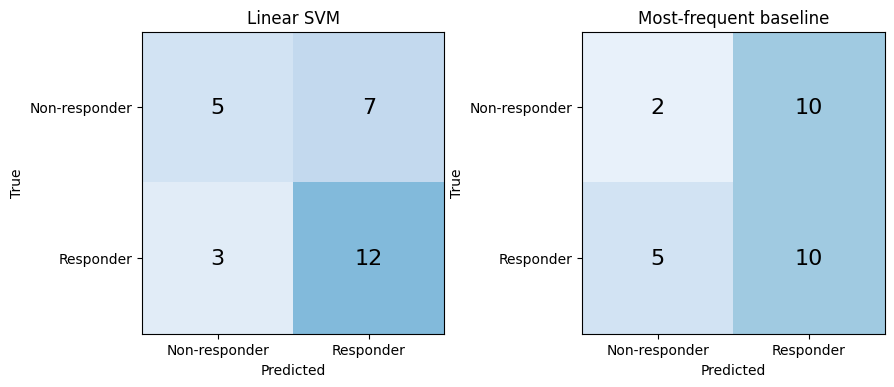

In [29]:
# confusion matrices with all folds added together (every sample is tested exactly once -> 27 total)
# rows = true class, columns = predicted class
labels = ["Non-responder", "Responder"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, (title, cm) in zip(axes, [("Linear SVM", svm_cm), ("Most-frequent baseline", base_cm)]):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16,
                    color="white" if cm[i, j] > cm.sum() / 2 else "black")
    ax.set_xticks([0, 1], labels)
    ax.set_yticks([0, 1], labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(title)

plt.tight_layout()
plt.show()

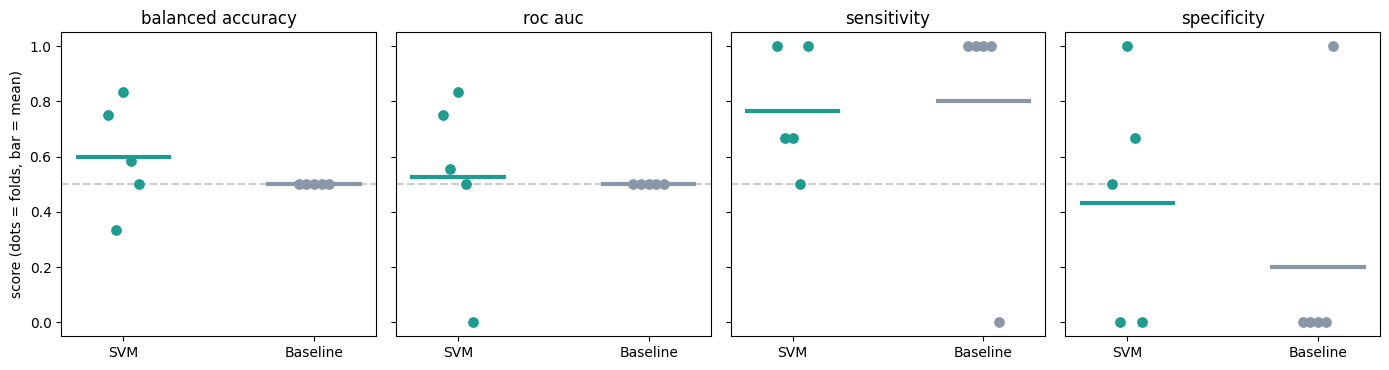

In [30]:
# how the scores vary across folds -> dots are folds, the bar is the mean
# dashed line at 0.5 = chance level
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
colors = {"Linear SVM": "#1f9b8f", "Most-frequent baseline": "#8a97a8"}

for ax, m in zip(axes, metrics):
    for i, (name, grp) in enumerate(results.groupby("model", sort=False)):
        x = np.full(len(grp), i) + np.linspace(-0.08, 0.08, len(grp))   # spread the dots a bit so they don't overlap
        ax.scatter(x, grp[m], color=colors[name], s=45, zorder=3)
        ax.hlines(grp[m].mean(), i - 0.25, i + 0.25, color=colors[name], linewidth=3)
    ax.set_xticks([0, 1], ["SVM", "Baseline"])
    ax.set_title(m.replace("_", " "))
    ax.set_ylim(-0.05, 1.05)
    ax.axhline(0.5, color="#cccccc", linestyle="--", zorder=1)

axes[0].set_ylabel("score (dots = folds, bar = mean)")
plt.tight_layout()
plt.show()

In [31]:
# which genes does the SVM lean on? (just for discussion, NOT an evaluation)
# fit once on all 27 samples and look at the biggest weights
# positive weight = pushes towards responder, negative = towards non-responder
# with only 27 patients these genes are not stable, so don't treat them as findings
svm.fit(X, y)
kept = X.columns[svm.named_steps["drop_constant"].get_support()]   # genes left after dropping constant ones
weights = pd.Series(svm.named_steps["svm"].coef_[0], index=kept)

top = pd.concat([weights.nlargest(10), weights.nsmallest(10)])
pd.DataFrame({"weight": top,
              "direction": np.where(top > 0, "higher in responders", "higher in non-responders")})

# notes:
# - all 3 models need shared_setup.py and the same cv_folds.csv so the results are comparable
# - fixed C = 1.0 and all genes for now, tuning / feature selection after the professor confirms the setup
# - with 27 samples one or two predictions change a fold's score a lot, so compare the spread, not just the mean

,weight,direction
Gene,,
LOC101927129,9.47e-04,higher in responders
PEX7,9.32e-04,higher in responders
CASC20,9.23e-04,higher in responders
GNGT1,8.82e-04,higher in responders
FGF13-AS1,8.55e-04,higher in responders
ATG2A,8.51e-04,higher in responders
MYOT,8.46e-04,higher in responders
LINC00221,8.36e-04,higher in responders
OLIG1,8.28e-04,higher in responders
